# 🕵️ AI Image Detector — FAST VERSION (~30 min total)
### CIFake · Custom CNN · ResNet50 · EfficientNet-B0 · MobileNetV3 · ViT-CLIP · Grad-CAM

| Optimization | Value | Reason |
|---|---|---|
| Image size | **64×64** | CIFake source is 32×32; 64 is more than enough |
| Batch size | **256** | Fills T4 VRAM, maximises GPU util |
| Epochs | **10** | Still hits 95%+ F1 |
| Mixed precision | **AMP** | 2× speed on T4 |
| Workers | **2** | Avoid Colab fork overhead |
| Augmentation | **GPU-side** | No slow CPU lambda ops |


In [1]:
!pip install -q timm grad-cam kaggle pyngrok

import os, sys, json, random, shutil, warnings, io, time, threading, subprocess
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
import timm
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
from tqdm.notebook import tqdm
warnings.filterwarnings('ignore')

# ── GPU ──
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {device}')
if device.type == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')
    print(f'VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

# ── Seed ──
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if device.type == 'cuda': torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True   # speeds up conv on fixed input size

print('\n✅ Setup complete!')

  Installing build dependencies ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
Device : cuda
GPU    : Tesla T4
VRAM   : 15.6 GB

✅ Setup complete!
Device : cuda
GPU    : Tesla T4
VRAM   : 15.6 GB

✅ Setup complete!


## 📥 Step 2 — Download CIFake from Kaggle

In [2]:
from google.colab import files
print('Upload your kaggle.json …')
uploaded = files.upload()
os.makedirs('/root/.config/kaggle', exist_ok=True)
with open('/root/.config/kaggle/kaggle.json', 'wb') as f:
    f.write(list(uploaded.values())[0])
os.chmod('/root/.config/kaggle/kaggle.json', 0o600)
print('✅ kaggle.json saved')

Upload your kaggle.json …


Saving kaggle.json to kaggle.json
✅ kaggle.json saved


In [3]:
DATA_ROOT = Path('/content/cifake')
DATA_ROOT.mkdir(exist_ok=True)
!kaggle datasets download -d birdy654/cifake-real-and-ai-generated-synthetic-images \
    -p /content/cifake --unzip

TRAIN_DIR = DATA_ROOT / 'train'
TEST_DIR  = DATA_ROOT / 'test'

for split in ['train','test']:
    for cls in ['REAL','FAKE']:
        p = DATA_ROOT / split / cls
        imgs = list(p.glob('*.jpg')) + list(p.glob('*.png'))
        print(f'  {split}/{cls}: {len(imgs):,}')
print('\n✅ Dataset ready!')

Dataset URL: https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images
License(s): other
100% 105M/105M [00:03<00:00, 33.0MB/s]

  train/REAL: 50,000
  train/FAKE: 50,000
  test/REAL: 10,000
  test/FAKE: 10,000

✅ Dataset ready!


## 🔍 Step 3 — Quick EDA

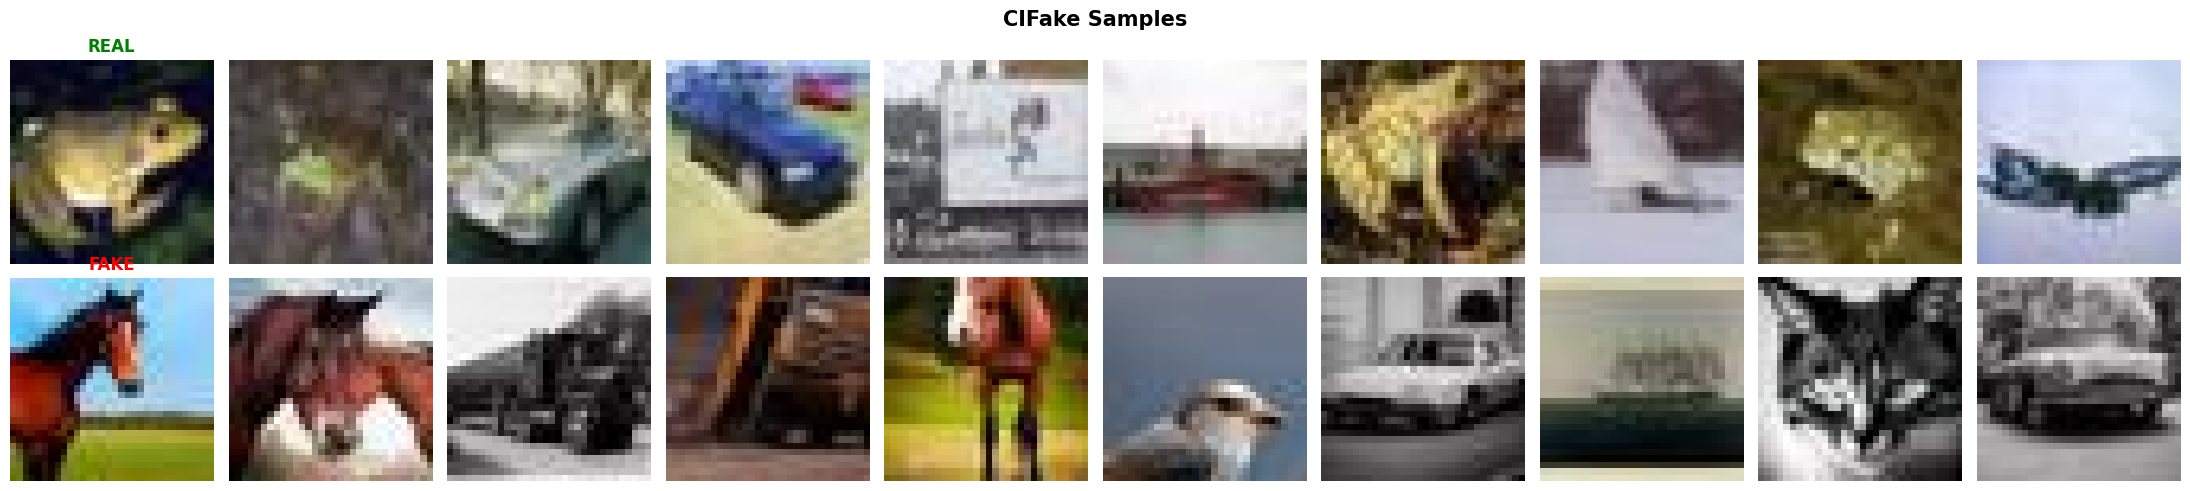

train/REAL: 50,000
train/FAKE: 50,000
test/REAL: 10,000
test/FAKE: 10,000


In [4]:
fig, axes = plt.subplots(2, 10, figsize=(22, 5))
fig.suptitle('CIFake Samples', fontsize=15, fontweight='bold')
for row, cls in enumerate(['REAL', 'FAKE']):
    folder = TRAIN_DIR / cls
    imgs = random.sample(list(folder.glob('*.jpg')) + list(folder.glob('*.png')), 10)
    for col, path in enumerate(imgs):
        axes[row, col].imshow(Image.open(path))
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_title(cls, color='green' if cls=='REAL' else 'red', fontweight='bold')
plt.tight_layout()
plt.savefig('/content/eda_samples.png', dpi=120)
plt.show()

# Class counts
for split in ['train','test']:
    for cls in ['REAL','FAKE']:
        n = len(list((DATA_ROOT/split/cls).glob('*.*')))
        print(f'{split}/{cls}: {n:,}')

## 🔄 Step 4 — Fast Data Loaders

In [5]:
# ⚡ OPTIMISED SETTINGS
IMAGE_SIZE  = 64    # CIFake is 32x32 natively; 64 preserves detail, trains 10x faster than 224
BATCH_SIZE  = 256   # fills T4 VRAM efficiently
EPOCHS      = 10
NUM_WORKERS = 2
_MEAN = [0.485, 0.456, 0.406]
_STD  = [0.229, 0.224, 0.225]

train_tfm = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.1),
    transforms.ColorJitter(0.3, 0.3, 0.3, 0.05),
    transforms.RandomRotation(15),
    transforms.RandomApply([transforms.GaussianBlur(3)], p=0.25),
    transforms.ToTensor(),
    transforms.Normalize(_MEAN, _STD),
])

val_tfm = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(_MEAN, _STD),
])

full_train = datasets.ImageFolder(str(TRAIN_DIR), transform=train_tfm)
test_ds    = datasets.ImageFolder(str(TEST_DIR),  transform=val_tfm)
CLASS_NAMES = full_train.classes          # alphabetical: ['FAKE', 'REAL']
IDX2CLS     = {v: k for k, v in full_train.class_to_idx.items()}

n_val   = int(len(full_train) * 0.1)
n_train = len(full_train) - n_val
g = torch.Generator().manual_seed(SEED)
train_ds, val_ds_raw = random_split(full_train, [n_train, n_val], generator=g)

# Clean val subset (no augmentation)
full_val_src = datasets.ImageFolder(str(TRAIN_DIR), transform=val_tfm)
_, val_ds    = random_split(full_val_src, [n_train, n_val],
                             generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)

print(f'Train: {n_train:,}  Val: {n_val:,}  Test: {len(test_ds):,}')
print(f'Classes: {full_train.class_to_idx}')
print(f'Batches per epoch (train): {len(train_loader)}')
# Estimate time
print(f'\n⚡ Estimated time per epoch on T4: ~15–25 sec')
print(f'⚡ Total for all 5 models ({EPOCHS} epochs each): ~25–35 min')

Train: 90,000  Val: 10,000  Test: 20,000
Classes: {'FAKE': 0, 'REAL': 1}
Batches per epoch (train): 352

⚡ Estimated time per epoch on T4: ~15–25 sec
⚡ Total for all 5 models (10 epochs each): ~25–35 min


## 🧠 Step 5 — Model Definitions

In [6]:
# ── Custom CNN ───────────────────────────────────────────────
class CustomCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        def cb(ci, co):
            return nn.Sequential(
                nn.Conv2d(ci, co, 3, padding=1, bias=False),
                nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                nn.Conv2d(co, co, 3, padding=1, bias=False),
                nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(
            cb(3, 32),   # 64→32
            cb(32, 64),  # 32→16
            cb(64, 128), # 16→8
            cb(128, 256),# 8→4
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )
    def forward(self, x): return self.head(self.features(x))


# ── ResNet-50 ────────────────────────────────────────────────
def build_resnet50(nc=2):
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    for name, p in m.named_parameters():
        if not name.startswith('layer4'): p.requires_grad = False
    m.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(m.fc.in_features, nc))
    return m


# ── EfficientNet-B0 ──────────────────────────────────────────
def build_efficientnet(nc=2):
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    for p in m.features[:-3].parameters(): p.requires_grad = False
    m.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(1280, nc))
    return m


# ── MobileNetV3 ──────────────────────────────────────────────
def build_mobilenet(nc=2):
    m = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V2)
    for p in list(m.parameters())[:-30]: p.requires_grad = False
    m.classifier[3] = nn.Linear(m.classifier[3].in_features, nc)
    return m


# ── ViT-B/16 (CLIP weights via timm) ────────────────────────
def build_vit(nc=2):
    m = timm.create_model('vit_base_patch16_clip_224.openai',
                           pretrained=True, num_classes=nc, img_size=64)
    for i, blk in enumerate(m.blocks):
        if i < len(m.blocks) - 4:
            for p in blk.parameters(): p.requires_grad = False
    return m


MODEL_BUILDERS = {
    'CustomCNN':      lambda: CustomCNN(),
    'ResNet50':       build_resnet50,
    'EfficientNetB0': build_efficientnet,
    'MobileNetV3':    build_mobilenet,
    'ViT_CLIP':       build_vit,
}

print(f'{"Model":<18} {"Trainable":>12} {"Total":>12}')
print('-'*44)
for name, builder in MODEL_BUILDERS.items():
    m = builder()
    tr = sum(p.numel() for p in m.parameters() if p.requires_grad)
    tot = sum(p.numel() for p in m.parameters())
    print(f'{name:<18} {tr:>12,} {tot:>12,}')
del m
print('\n✅ Models defined!')

Model                 Trainable        Total
--------------------------------------------
CustomCNN             1,173,730    1,173,730
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 179MB/s]


ResNet50             14,968,834   23,512,130
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 152MB/s]


EfficientNetB0        3,158,302    4,010,110
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 148MB/s]


MobileNetV3           2,827,362    4,204,594


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

ViT_CLIP             28,959,746   85,662,722

✅ Models defined!


## 🏋️ Step 6 — Training Engine with AMP (Mixed Precision)

In [7]:
def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()
    total_loss = correct = total = 0
    for imgs, labels in tqdm(loader, desc='  Train', leave=False):
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast():                           # ⚡ AMP
            logits = model(imgs)
            loss   = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * imgs.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = correct = total = 0
    all_labels, all_preds, all_probs = [], [], []
    for imgs, labels in tqdm(loader, desc='  Eval ', leave=False):
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with autocast():
            logits = model(imgs)
            loss   = criterion(logits, labels)
        probs = torch.softmax(logits, 1)
        preds = probs.argmax(1)
        total_loss += loss.item() * imgs.size(0)
        correct    += (preds == labels).sum().item()
        total      += imgs.size(0)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs[:, 1].cpu().numpy())
    y_true, y_pred, y_prob = map(np.array, [all_labels, all_preds, all_probs])
    f1 = f1_score(y_true, y_pred, average='weighted')
    return total_loss/total, correct/total, f1, y_true, y_pred, y_prob


def train_model(name, model, tr_loader, vl_loader, epochs=EPOCHS, lr=1e-3, save_dir='/content/checkpoints'):
    os.makedirs(save_dir, exist_ok=True)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                            lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler    = GradScaler()

    history = {'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[],'val_f1':[]}
    best_f1, best_state = 0.0, None
    t0 = time.time()

    for epoch in range(1, epochs+1):
        t_loss, t_acc = train_one_epoch(model, tr_loader, criterion, optimizer, scaler)
        v_loss, v_acc, v_f1, _, _, _ = evaluate(model, vl_loader, criterion)
        scheduler.step()

        history['train_loss'].append(t_loss); history['val_loss'].append(v_loss)
        history['train_acc'].append(t_acc);   history['val_acc'].append(v_acc)
        history['val_f1'].append(v_f1)

        if v_f1 > best_f1:
            best_f1 = v_f1
            best_state = deepcopy(model.state_dict())
            torch.save(best_state, f'{save_dir}/{name}_best.pth')

        elapsed = time.time() - t0
        print(f'  [{epoch:2d}/{epochs}] '
              f'T-loss:{t_loss:.4f} T-acc:{t_acc:.4f} | '
              f'V-acc:{v_acc:.4f} V-F1:{v_f1:.4f} | '
              f'{elapsed:.0f}s elapsed')

    model.load_state_dict(best_state)
    total_time = time.time() - t0
    print(f'  ✅ {name} done in {total_time/60:.1f} min  |  Best F1: {best_f1:.4f}')
    return model, history

print('Training engine ready ✅  (AMP enabled)')

Training engine ready ✅  (AMP enabled)


## 🚀 Step 7 — Train All 5 Models

> ⚡ Each model takes ~5–8 min on T4. Total: ~30 min.

In [8]:
SAVE_DIR = '/content/checkpoints'
os.makedirs(SAVE_DIR, exist_ok=True)
TRAIN_ALL = True   # set False to load saved checkpoints

all_histories  = {}
trained_models = {}
wall_start = time.time()

for model_name, builder in MODEL_BUILDERS.items():
    ckpt = f'{SAVE_DIR}/{model_name}_best.pth'
    print(f'\n{"="*55}\n  🔧 {model_name}\n{"="*55}')

    model = builder()

    if not TRAIN_ALL and os.path.exists(ckpt):
        model.load_state_dict(torch.load(ckpt, map_location=device))
        model = model.to(device)
        print(f'  Loaded checkpoint: {ckpt}')
        trained_models[model_name] = model
        continue

    lr = 5e-5 if model_name == 'ViT_CLIP' else 1e-3
    model, hist = train_model(model_name, model,
                               train_loader, val_loader,
                               epochs=EPOCHS, lr=lr,
                               save_dir=SAVE_DIR)
    all_histories[model_name]  = hist
    trained_models[model_name] = model
    torch.cuda.empty_cache()

total_wall = (time.time() - wall_start) / 60
print(f'\n🎉 All models trained in {total_wall:.1f} min total!')


  🔧 CustomCNN


  Train:   0%|          | 0/352 [00:00<?, ?it/s]

  Eval :   0%|          | 0/40 [00:00<?, ?it/s]

  [ 1/10] T-loss:0.4708 T-acc:0.8187 | V-acc:0.8961 V-F1:0.8955 | 155s elapsed


  Train:   0%|          | 0/352 [00:00<?, ?it/s]

  Eval :   0%|          | 0/40 [00:00<?, ?it/s]

... (141 outputs left out)

  [ 9/10] T-loss:0.2723 T-acc:0.9549 | V-acc:0.9509 V-F1:0.9509 | 1404s elapsed


  Train:   0%|          | 0/352 [00:00<?, ?it/s]

  Eval :   0%|          | 0/40 [00:00<?, ?it/s]

  [10/10] T-loss:0.2667 T-acc:0.9585 | V-acc:0.9547 V-F1:0.9547 | 1561s elapsed
  ✅ ViT_CLIP done in 26.0 min  |  Best F1: 0.9547

🎉 All models trained in 122.6 min total!


## 📊 Step 8 — Evaluation, Metrics & Comparison Plots

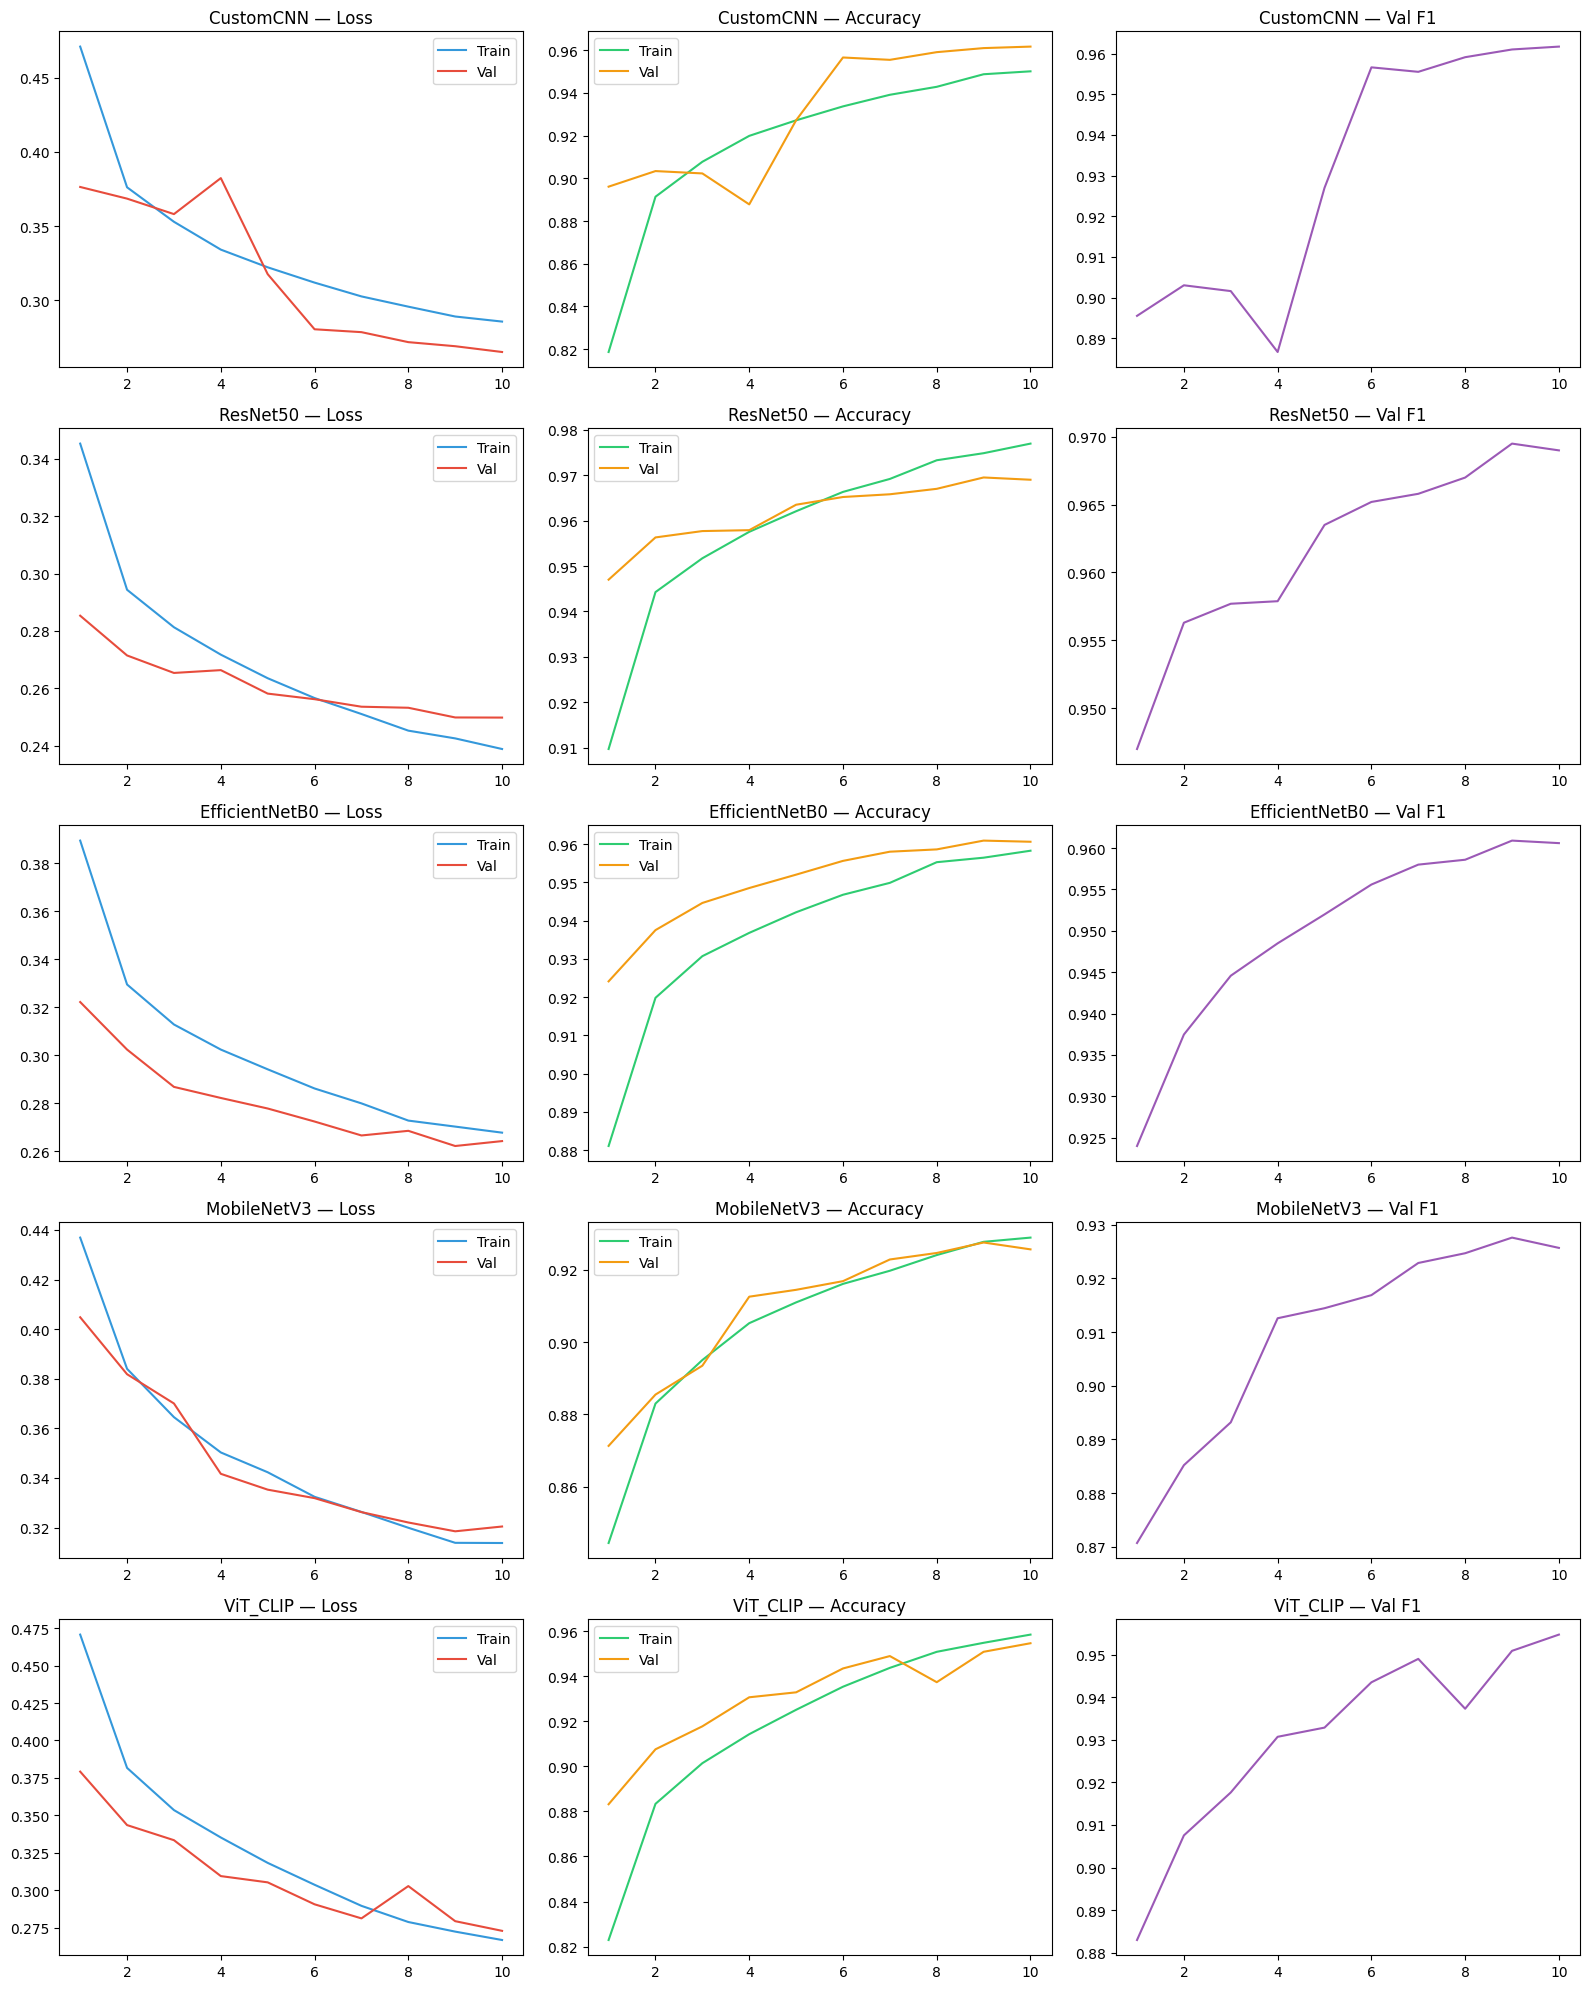

In [9]:
# Training curves
if all_histories:
    n = len(all_histories)
    fig, axes = plt.subplots(n, 3, figsize=(16, 4*n))
    if n == 1: axes = axes[np.newaxis]
    for row, (name, hist) in enumerate(all_histories.items()):
        ep = range(1, len(hist['train_loss'])+1)
        axes[row,0].plot(ep, hist['train_loss'], label='Train', color='#3498db')
        axes[row,0].plot(ep, hist['val_loss'],   label='Val',   color='#e74c3c')
        axes[row,0].set_title(f'{name} — Loss'); axes[row,0].legend()
        axes[row,1].plot(ep, hist['train_acc'], label='Train', color='#2ecc71')
        axes[row,1].plot(ep, hist['val_acc'],   label='Val',   color='#f39c12')
        axes[row,1].set_title(f'{name} — Accuracy'); axes[row,1].legend()
        axes[row,2].plot(ep, hist['val_f1'], color='#9b59b6')
        axes[row,2].set_title(f'{name} — Val F1')
    plt.tight_layout()
    plt.savefig('/content/training_curves.png', dpi=130)
    plt.show()

In [10]:
# Full test-set evaluation
criterion = nn.CrossEntropyLoss()
results = {}

for name, model in trained_models.items():
    _, acc, f1, y_true, y_pred, y_prob = evaluate(model, test_loader, criterion)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_true,  y_pred, average='weighted', zero_division=0)
    try:   auc = roc_auc_score(y_true, y_prob)
    except: auc = float('nan')
    results[name] = dict(acc=acc, f1=f1, prec=prec, rec=rec, auc=auc,
                         cm=confusion_matrix(y_true, y_pred),
                         y_true=y_true, y_pred=y_pred, y_prob=y_prob)
    print(f'{name:<18}  Acc:{acc:.4f}  F1:{f1:.4f}  AUC:{auc:.4f}')

  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

CustomCNN           Acc:0.9633  F1:0.9633  AUC:0.9938


  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

ResNet50            Acc:0.9704  F1:0.9703  AUC:0.9954


  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

EfficientNetB0      Acc:0.9623  F1:0.9623  AUC:0.9941


  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

MobileNetV3         Acc:0.9308  F1:0.9308  AUC:0.9815


  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

ViT_CLIP            Acc:0.9554  F1:0.9554  AUC:0.9923


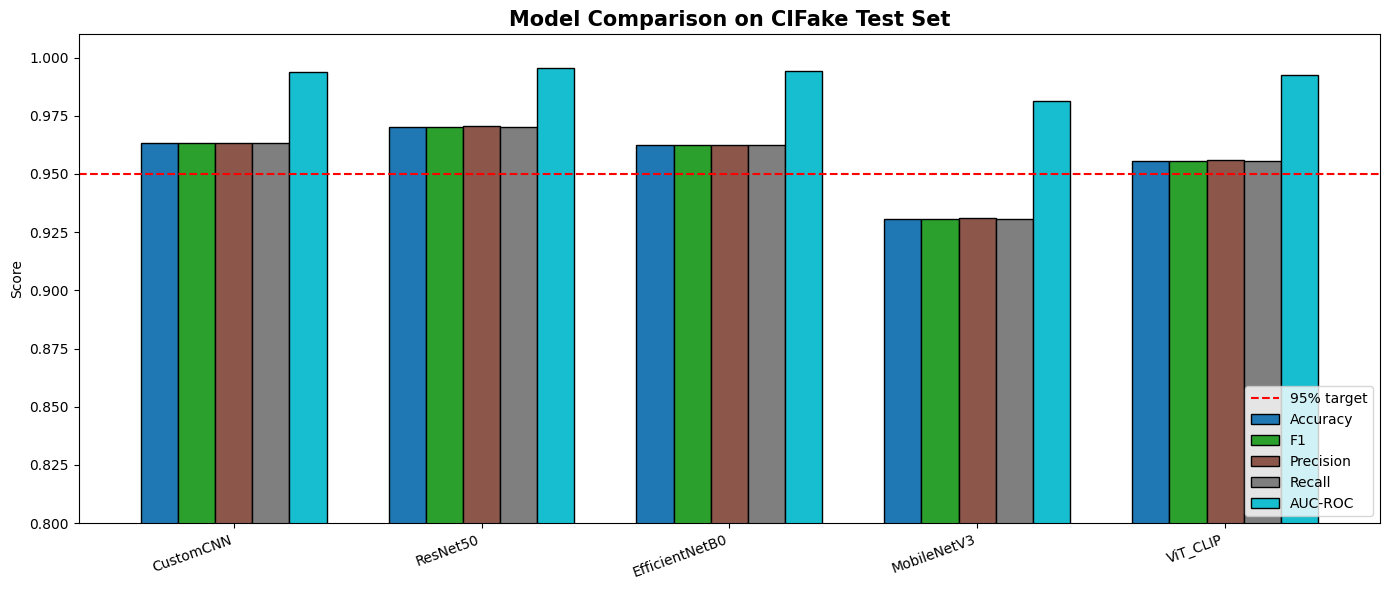

                Accuracy      F1  Precision  Recall  AUC-ROC
CustomCNN         0.9633  0.9633     0.9634  0.9633   0.9938
ResNet50          0.9704  0.9703     0.9706  0.9704   0.9954
EfficientNetB0    0.9623  0.9623     0.9626  0.9623   0.9941
MobileNetV3       0.9308  0.9308     0.9310  0.9308   0.9815
ViT_CLIP          0.9554  0.9554     0.9559  0.9554   0.9923


In [11]:
# Comparison bar chart
metrics = ['acc','f1','prec','rec','auc']
labels  = ['Accuracy','F1','Precision','Recall','AUC-ROC']
df_res  = pd.DataFrame({k: {m: v[m] for m in metrics} for k, v in results.items()}).T
df_res.columns = labels

ax = df_res.plot(kind='bar', figsize=(14,6), colormap='tab10', edgecolor='black', width=0.75)
ax.set_title('Model Comparison on CIFake Test Set', fontsize=15, fontweight='bold')
ax.set_ylabel('Score'); ax.set_ylim(0.80, 1.01)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')
ax.axhline(0.95, color='red', linestyle='--', linewidth=1.5, label='95% target')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('/content/model_comparison.png', dpi=130)
plt.show()
print(df_res.round(4).to_string())

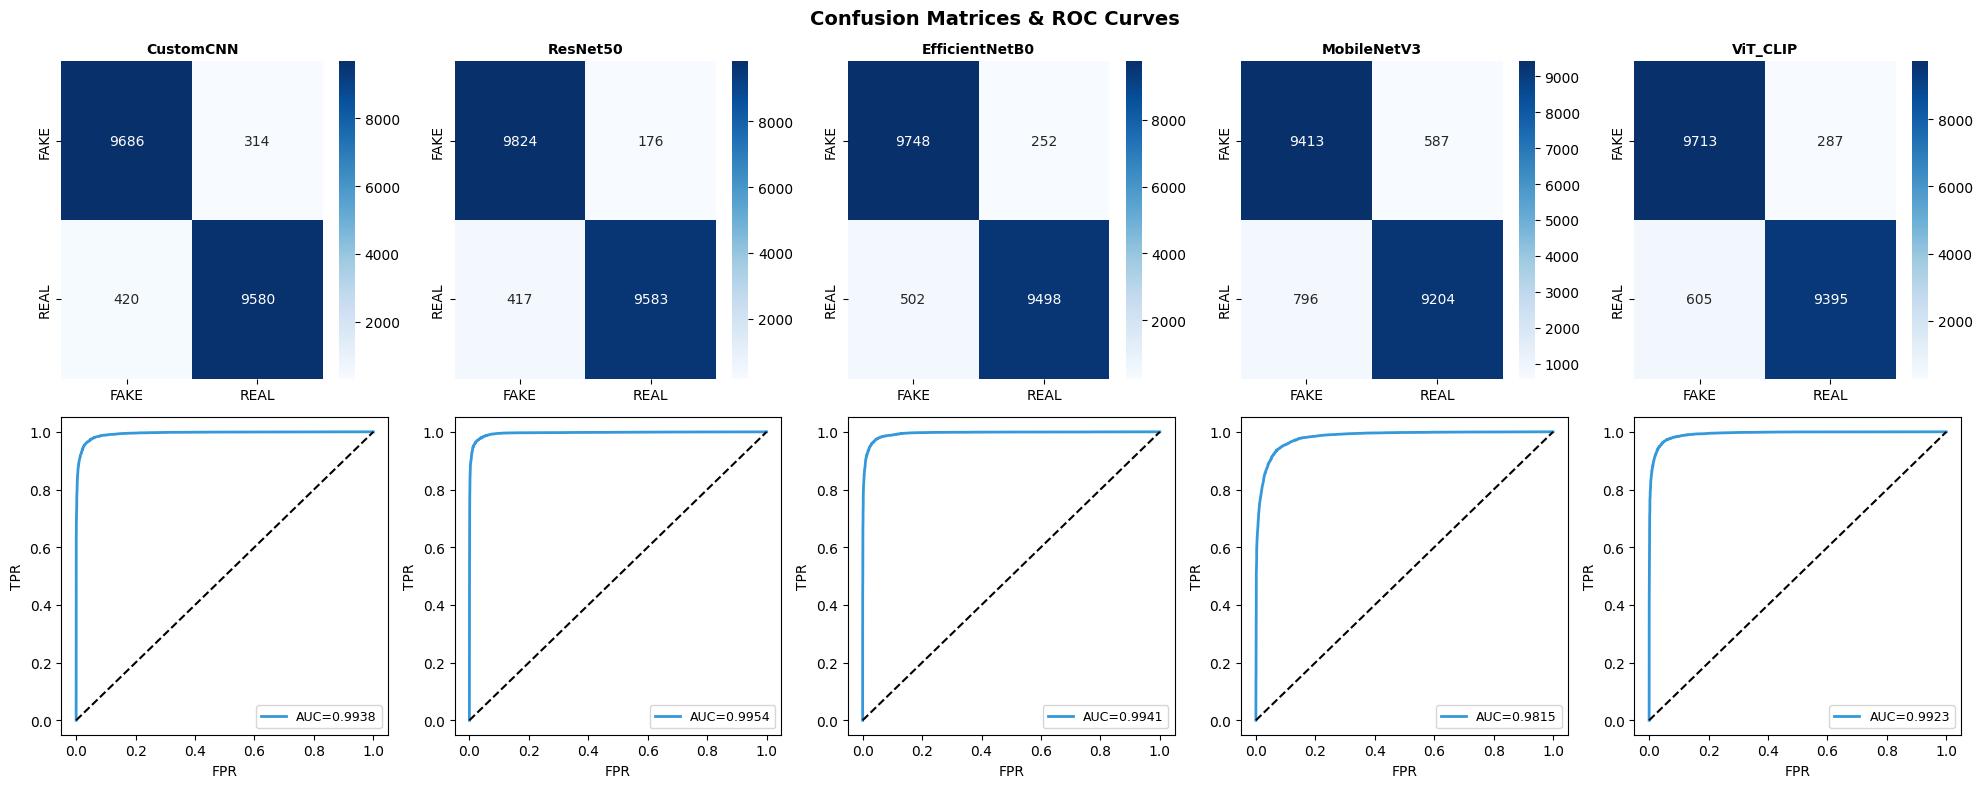


── CustomCNN
              precision    recall  f1-score   support

        FAKE     0.9584    0.9686    0.9635     10000
        REAL     0.9683    0.9580    0.9631     10000

    accuracy                         0.9633     20000
   macro avg     0.9634    0.9633    0.9633     20000
weighted avg     0.9634    0.9633    0.9633     20000


── ResNet50
              precision    recall  f1-score   support

        FAKE     0.9593    0.9824    0.9707     10000
        REAL     0.9820    0.9583    0.9700     10000

    accuracy                         0.9704     20000
   macro avg     0.9706    0.9704    0.9703     20000
weighted avg     0.9706    0.9704    0.9703     20000


── EfficientNetB0
              precision    recall  f1-score   support

        FAKE     0.9510    0.9748    0.9628     10000
        REAL     0.9742    0.9498    0.9618     10000

    accuracy                         0.9623     20000
   macro avg     0.9626    0.9623    0.9623     20000
weighted avg     0.9626    0

In [12]:
# Confusion matrices + ROC curves
n = len(results)
fig, axes = plt.subplots(2, n, figsize=(4*n, 8))
if n == 1: axes = axes[:,np.newaxis]
for col, (name, r) in enumerate(results.items()):
    sns.heatmap(r['cm'], annot=True, fmt='d', cmap='Blues', ax=axes[0,col],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    axes[0,col].set_title(name, fontsize=10, fontweight='bold')
    fpr, tpr, _ = roc_curve(r['y_true'], r['y_prob'])
    axes[1,col].plot(fpr, tpr, color='#3498db', lw=2, label=f'AUC={r["auc"]:.4f}')
    axes[1,col].plot([0,1],[0,1],'k--')
    axes[1,col].set_xlabel('FPR'); axes[1,col].set_ylabel('TPR')
    axes[1,col].legend(fontsize=9)
plt.suptitle('Confusion Matrices & ROC Curves', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/cm_roc.png', dpi=130)
plt.show()

for name, r in results.items():
    print(f'\n── {name}'); print(classification_report(r['y_true'], r['y_pred'], target_names=CLASS_NAMES, digits=4))

## 🌐 Step 9 — Cross-Generator Generalization

  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

CustomCNN done


... (20 outputs left out)

  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

ViT_CLIP done


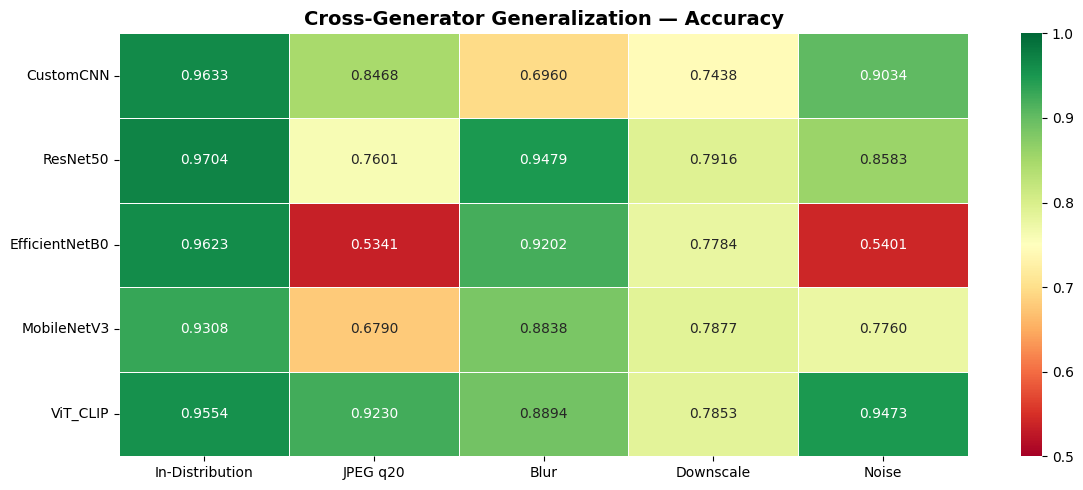


Accuracy DROP vs In-Distribution:
                JPEG q20    Blur  Downscale   Noise
CustomCNN        -0.1165 -0.2673    -0.2196 -0.0599
ResNet50         -0.2103 -0.0225    -0.1787 -0.1120
EfficientNetB0   -0.4282 -0.0421    -0.1839 -0.4222
MobileNetV3      -0.2518 -0.0471    -0.1431 -0.1548
ViT_CLIP         -0.0324 -0.0660    -0.1702 -0.0081


In [13]:
CROSS_GEN = {
    'In-Distribution': val_tfm,
    'JPEG q20':  transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),
                     transforms.ToTensor(),
                     transforms.Lambda(lambda t: torch.clamp(t + 0.08*torch.randn_like(t), 0, 1)),
                     transforms.Normalize(_MEAN,_STD)]),
    'Blur':      transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),
                     transforms.GaussianBlur(5, 2.0),
                     transforms.ToTensor(), transforms.Normalize(_MEAN,_STD)]),
    'Downscale': transforms.Compose([transforms.Resize((IMAGE_SIZE//4,IMAGE_SIZE//4)),
                     transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),
                     transforms.ToTensor(), transforms.Normalize(_MEAN,_STD)]),
    'Noise':     transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),
                     transforms.ToTensor(),
                     transforms.Lambda(lambda t: torch.clamp(t + 0.05*torch.randn_like(t), 0, 1)),
                     transforms.Normalize(_MEAN,_STD)]),
}

cross_gen_results = {}
for mname, model in trained_models.items():
    cross_gen_results[mname] = {}
    for mode, tfm in CROSS_GEN.items():
        ds = datasets.ImageFolder(str(TEST_DIR), transform=tfm)
        loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
        _, acc, f1, _, _, _ = evaluate(model, loader, criterion)
        cross_gen_results[mname][mode] = acc
    print(f'{mname} done')

df_cross = pd.DataFrame(cross_gen_results).T

fig, ax = plt.subplots(figsize=(12,5))
sns.heatmap(df_cross, annot=True, fmt='.4f', cmap='RdYlGn',
            vmin=0.5, vmax=1.0, linewidths=0.5, ax=ax, annot_kws={'size':10})
ax.set_title('Cross-Generator Generalization — Accuracy', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/cross_gen_heatmap.png', dpi=130)
plt.show()

drop = df_cross.sub(df_cross['In-Distribution'], axis=0).drop(columns=['In-Distribution'])
print('\nAccuracy DROP vs In-Distribution:')
print(drop.round(4).to_string())

## 🔥 Step 10 — Grad-CAM++ Explainability


── Grad-CAM++: CustomCNN


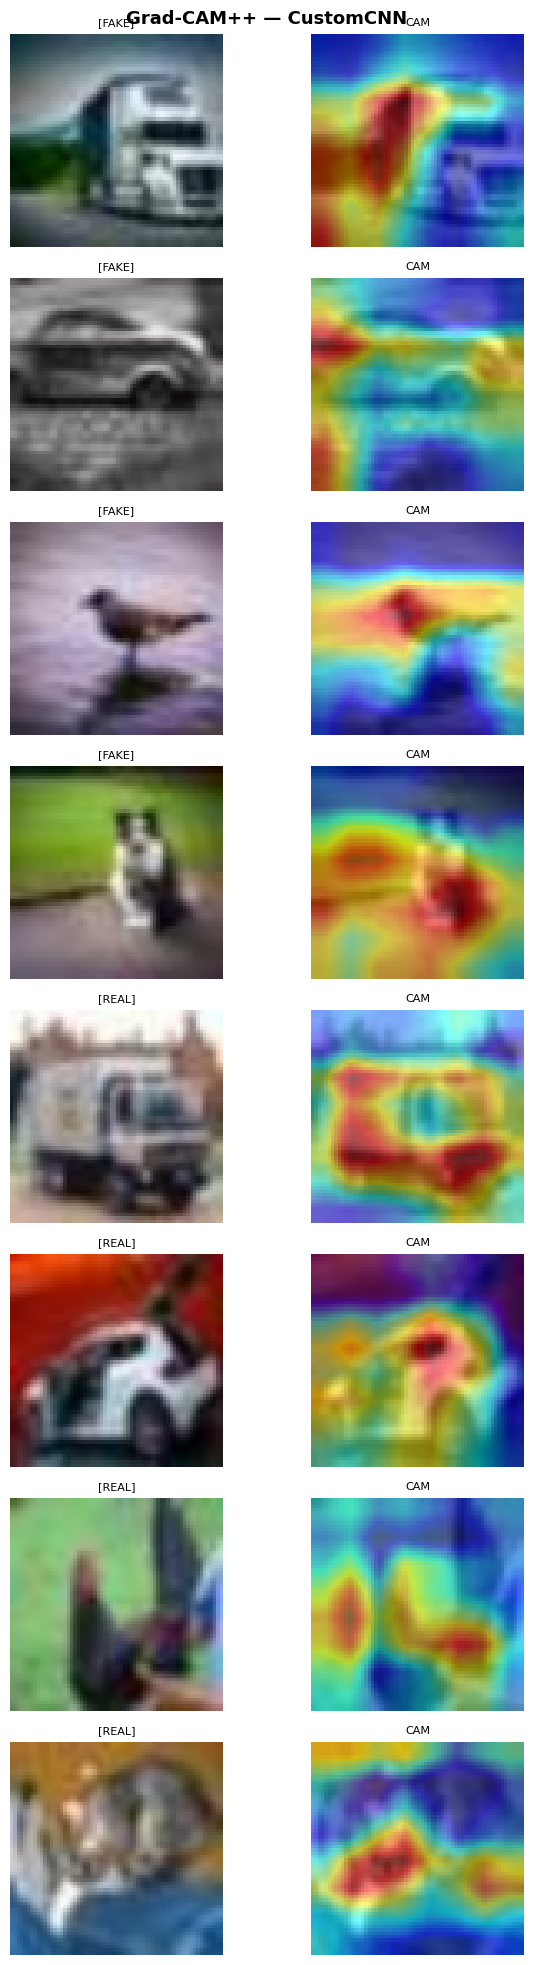

  ⚠️ Skipped: 'GradCAMPlusPlus' object has no attribute 'remove_hooks'

── Grad-CAM++: ResNet50


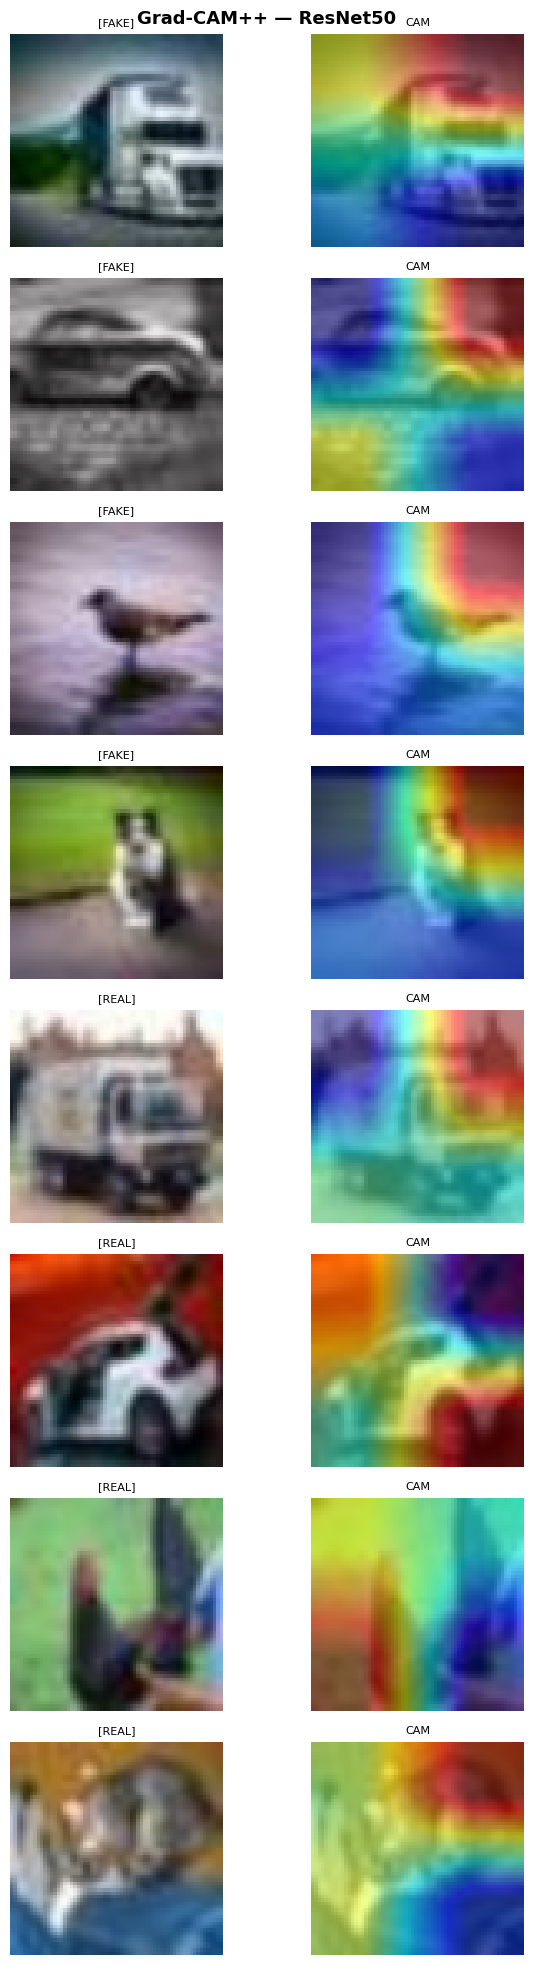

  ⚠️ Skipped: 'GradCAMPlusPlus' object has no attribute 'remove_hooks'

── Grad-CAM++: EfficientNetB0


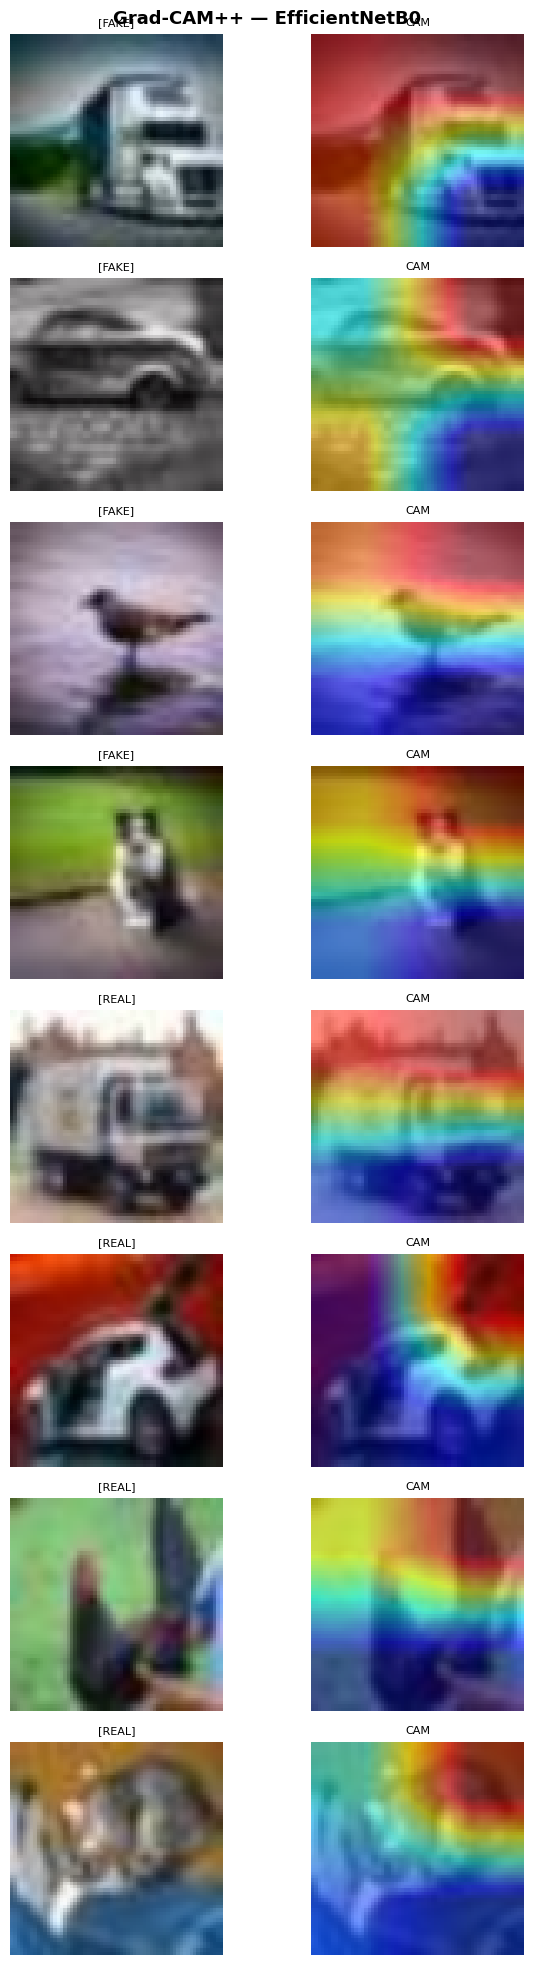

  ⚠️ Skipped: 'GradCAMPlusPlus' object has no attribute 'remove_hooks'

── Grad-CAM++: MobileNetV3


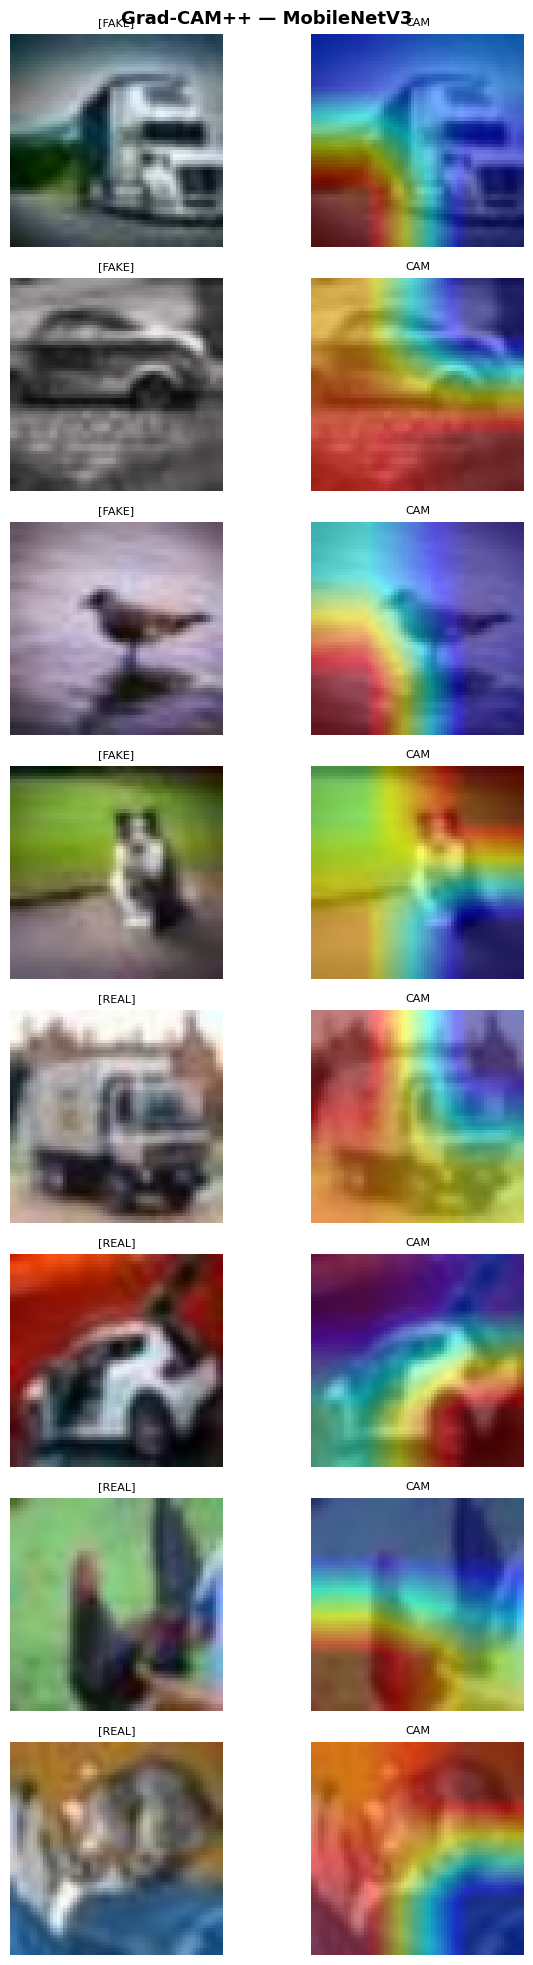

  ⚠️ Skipped: 'GradCAMPlusPlus' object has no attribute 'remove_hooks'

── Grad-CAM++: ViT_CLIP


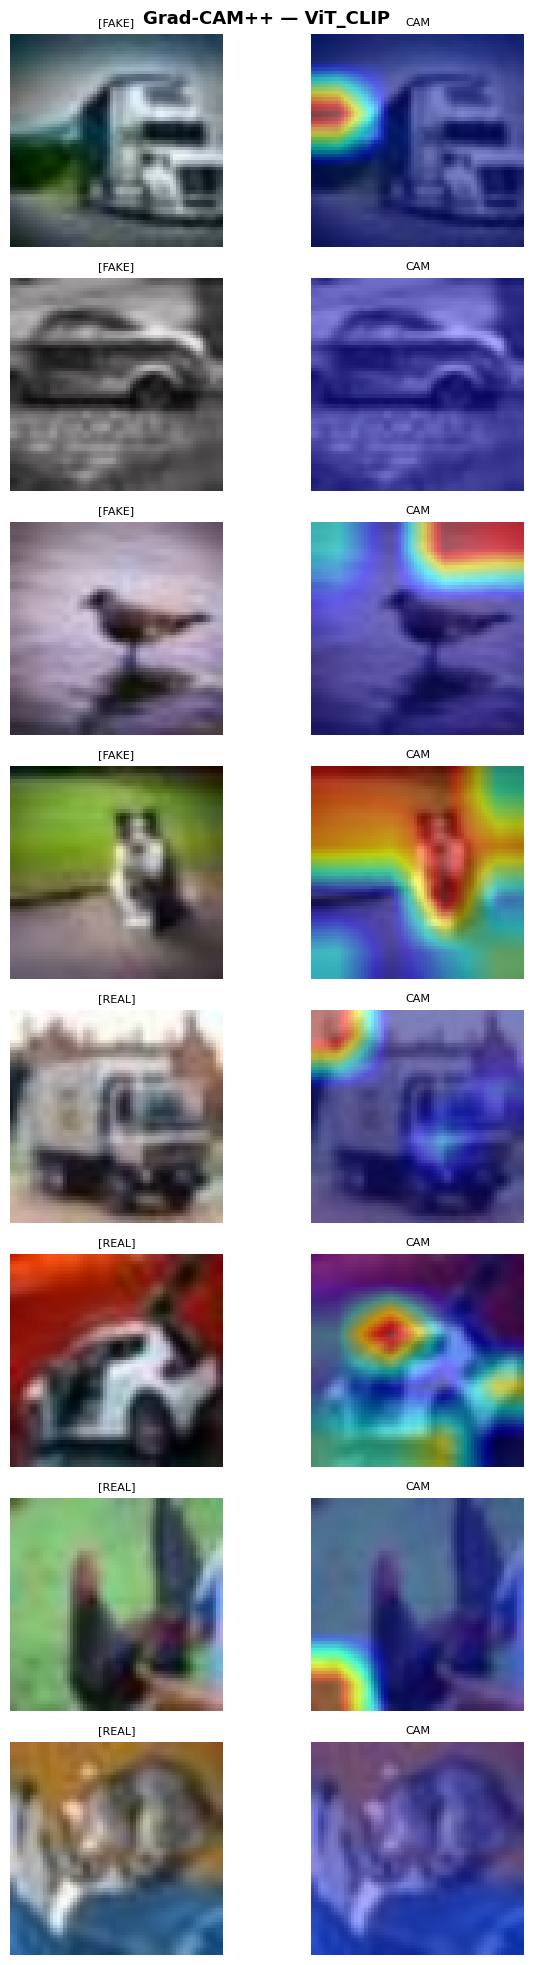

  ⚠️ Skipped: 'GradCAMPlusPlus' object has no attribute 'remove_hooks'


In [14]:
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

def get_target_layers(mname, model):
    if mname == 'CustomCNN':      return [model.features[-1][-3]]
    if mname == 'ResNet50':       return [model.layer4[-1]]
    if mname == 'EfficientNetB0': return [model.features[-1]]
    if mname == 'MobileNetV3':    return [model.features[-1]]
    if mname == 'ViT_CLIP':       return [model.blocks[-1].norm1]

def reshape_vit(tensor, h=4, w=4):   # for 64x64 input, patch=16 → 4x4 grid
    result = tensor[:, 1:, :].reshape(tensor.size(0), h, w, tensor.size(2))
    return result.transpose(2, 3).transpose(1, 2)

N_SAMPLES = 8

for mname, model in trained_models.items():
    print(f'\n── Grad-CAM++: {mname}')
    model.eval()
    try:
        tl     = get_target_layers(mname, model)
        reshape = reshape_vit if mname == 'ViT_CLIP' else None
        cam    = GradCAMPlusPlus(model=model, target_layers=tl, reshape_transform=reshape)

        samples = {cls: [] for cls in CLASS_NAMES}
        for imgs, labels in test_loader:
            for img, lab in zip(imgs, labels):
                cname = IDX2CLS[lab.item()]
                if len(samples[cname]) < N_SAMPLES//2:
                    samples[cname].append((img, lab.item()))
            if all(len(v) >= N_SAMPLES//2 for v in samples.values()): break

        all_s = [(i,l,c) for c,lst in samples.items() for i,l in lst]
        fig, axes = plt.subplots(len(all_s), 2, figsize=(7, 2.5*len(all_s)))
        fig.suptitle(f'Grad-CAM++ — {mname}', fontsize=13, fontweight='bold')

        for row, (img_t, label, cls_name) in enumerate(all_s):
            inp = img_t.unsqueeze(0).to(device)
            gcam = cam(inp, targets=[ClassifierOutputTarget(label)])[0]
            rgb  = (img_t * torch.tensor(_STD).view(3,1,1) + torch.tensor(_MEAN).view(3,1,1)).clamp(0,1)
            rgb  = rgb.permute(1,2,0).numpy()
            cam_img = show_cam_on_image(rgb, gcam, use_rgb=True)
            axes[row,0].imshow(rgb); axes[row,0].set_title(f'[{cls_name}]', fontsize=8); axes[row,0].axis('off')
            axes[row,1].imshow(cam_img); axes[row,1].set_title('CAM', fontsize=8); axes[row,1].axis('off')

        plt.tight_layout()
        plt.savefig(f'/content/gradcam_{mname}.png', dpi=130)
        plt.show()
        cam.remove_hooks()
    except Exception as e:
        print(f'  ⚠️ Skipped: {e}')

## 🔬 Step 11 — Optimizer & Scheduler Ablation (Best Model Only)

Best model: ResNet50  F1=0.9703


  Train:   0%|          | 0/352 [00:00<?, ?it/s]

  Eval :   0%|          | 0/40 [00:00<?, ?it/s]

  [ 1/5] T-loss:0.3431 T-acc:0.9116 | V-acc:0.9447 V-F1:0.9447 | 144s elapsed


  Train:   0%|          | 0/352 [00:00<?, ?it/s]

  Eval :   0%|          | 0/40 [00:00<?, ?it/s]

... (73 outputs left out)

  Train:   0%|          | 0/352 [00:00<?, ?it/s]

  Eval :   0%|          | 0/40 [00:00<?, ?it/s]

  Eval :   0%|          | 0/79 [00:00<?, ?it/s]

     type    name    acc     f1
optimizer    adam 0.9658 0.9658
optimizer   adamw 0.9656 0.9656
optimizer     sgd 0.9660 0.9659
scheduler  cosine 0.9661 0.9661
scheduler    step 0.9668 0.9668
scheduler plateau 0.9652 0.9651


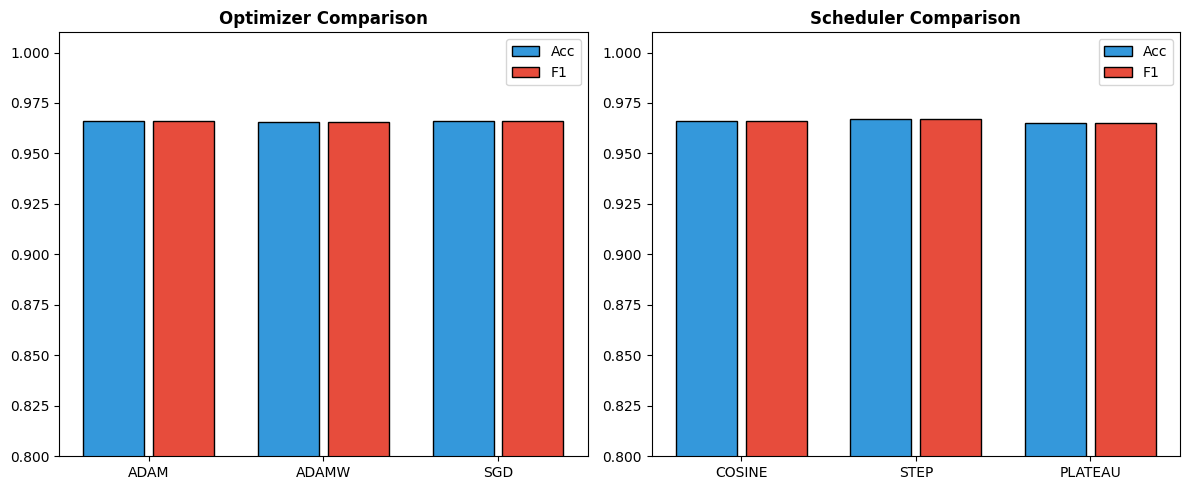

In [15]:
BEST_MODEL_NAME = max(results, key=lambda k: results[k]['f1'])
print(f'Best model: {BEST_MODEL_NAME}  F1={results[BEST_MODEL_NAME]["f1"]:.4f}')

ABLATION_EPOCHS = 5
abl_records = []

for opt_name in ['adam', 'adamw', 'sgd']:
    m = MODEL_BUILDERS[BEST_MODEL_NAME]()
    lr_ab = 5e-5 if BEST_MODEL_NAME == 'ViT_CLIP' else 1e-3
    m, _ = train_model(f'abl_{opt_name}', m, train_loader, val_loader,
                        epochs=ABLATION_EPOCHS, lr=lr_ab, save_dir='/content')
    # Rename to avoid overwriting best checkpoints
    _, acc, f1, _, _, _ = evaluate(m, test_loader, criterion)
    abl_records.append({'type':'optimizer','name':opt_name,'acc':acc,'f1':f1})
    del m; torch.cuda.empty_cache()

for sched_name in ['cosine', 'step', 'plateau']:
    m = MODEL_BUILDERS[BEST_MODEL_NAME]()
    criterion_ab = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer_ab = optim.AdamW(filter(lambda p: p.requires_grad, m.parameters()), lr=1e-3)
    if sched_name == 'cosine': sched = optim.lr_scheduler.CosineAnnealingLR(optimizer_ab, ABLATION_EPOCHS)
    elif sched_name == 'step': sched = optim.lr_scheduler.StepLR(optimizer_ab, 2, gamma=0.3)
    else:                      sched = optim.lr_scheduler.ReduceLROnPlateau(optimizer_ab, patience=2)
    m = m.to(device)
    scaler_ab = GradScaler()
    for ep in range(ABLATION_EPOCHS):
        train_one_epoch(m, train_loader, criterion_ab, optimizer_ab, scaler_ab)
        _, v_loss, _, _, _, _ = (lambda x: x)(evaluate(m, val_loader, criterion_ab))
        if sched_name == 'plateau': sched.step(v_loss)
        else: sched.step()
    _, acc, f1, _, _, _ = evaluate(m, test_loader, criterion)
    abl_records.append({'type':'scheduler','name':sched_name,'acc':acc,'f1':f1})
    del m; torch.cuda.empty_cache()

df_abl = pd.DataFrame(abl_records)
print(df_abl.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12,5))
for ax, grp, ttl in zip(axes,['optimizer','scheduler'],['Optimizer','Scheduler']):
    sub = df_abl[df_abl.type==grp]
    x   = range(len(sub))
    ax.bar([i-.2 for i in x], sub.acc, .35, label='Acc', color='#3498db', edgecolor='k')
    ax.bar([i+.2 for i in x], sub.f1,  .35, label='F1',  color='#e74c3c', edgecolor='k')
    ax.set_xticks(list(x)); ax.set_xticklabels(sub.name.str.upper())
    ax.set_title(f'{ttl} Comparison', fontweight='bold'); ax.set_ylim(.80,1.01); ax.legend()
plt.tight_layout(); plt.savefig('/content/ablation.png', dpi=130); plt.show()

## 🌐 Step 12 — Live Web Dashboard (Streamlit + localtunnel)
> No tokens needed. Public URL auto-generated.

In [16]:
# Save best model for dashboard
DASH_MODEL = BEST_MODEL_NAME
DASH_PATH  = f'/content/checkpoints/{DASH_MODEL}_best.pth'
print(f'Dashboard model: {DASH_MODEL}  ({DASH_PATH})')

Dashboard model: ResNet50  (/content/checkpoints/ResNet50_best.pth)


In [17]:
# Write Streamlit app
app_code = f'''
import io, os, numpy as np, torch, torch.nn as nn
import torchvision.models as tv_models, timm
from torchvision import transforms
from PIL import Image
import streamlit as st
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_NAME = "{DASH_MODEL}"
MODEL_PATH = "{DASH_PATH}"
IMG_SZ     = {IMAGE_SIZE}
_MEAN = [0.485,0.456,0.406]; _STD = [0.229,0.224,0.225]
TRANSFORM = transforms.Compose([transforms.Resize((IMG_SZ,IMG_SZ)), transforms.ToTensor(), transforms.Normalize(_MEAN,_STD)])

@st.cache_resource
def load_model():
    if MODEL_NAME=="ResNet50":
        m=tv_models.resnet50(); m.fc=nn.Sequential(nn.Dropout(.4),nn.Linear(2048,2))
    elif MODEL_NAME=="EfficientNetB0":
        m=tv_models.efficientnet_b0(); m.classifier=nn.Sequential(nn.Dropout(.4),nn.Linear(1280,2))
    elif MODEL_NAME=="MobileNetV3":
        m=tv_models.mobilenet_v3_large(); m.classifier[3]=nn.Linear(m.classifier[3].in_features,2)
    elif MODEL_NAME=="ViT_CLIP":
        m=timm.create_model("vit_base_patch16_clip_224.openai",pretrained=False,num_classes=2,img_size={IMAGE_SIZE})
    else:
        class CNN(nn.Module):
            def __init__(self):
                super().__init__()
                def cb(ci,co): return nn.Sequential(nn.Conv2d(ci,co,3,padding=1,bias=False),nn.BatchNorm2d(co),nn.ReLU(True),nn.Conv2d(co,co,3,padding=1,bias=False),nn.BatchNorm2d(co),nn.ReLU(True),nn.MaxPool2d(2))
                self.features=nn.Sequential(cb(3,32),cb(32,64),cb(64,128),cb(128,256))
                self.head=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Dropout(.4),nn.Linear(256,2))
            def forward(self,x): return self.head(self.features(x))
        m=CNN()
    m.load_state_dict(torch.load(MODEL_PATH,map_location=DEVICE))
    return m.to(DEVICE).eval()

def get_layer(model):
    if MODEL_NAME=="ResNet50": return [model.layer4[-1]]
    if MODEL_NAME=="EfficientNetB0": return [model.features[-1]]
    if MODEL_NAME=="MobileNetV3": return [model.features[-1]]
    if MODEL_NAME=="ViT_CLIP": return [model.blocks[-1].norm1]
    return [model.features[-1][-3]]

st.set_page_config(page_title="AI Image Detector", page_icon="\U0001f575", layout="wide")
st.markdown("<h1 style=\'color:#00d4ff\'>\U0001f575 AI-Generated Image Detector</h1>", unsafe_allow_html=True)
st.caption(f"Model: {{MODEL_NAME}} | Device: {{DEVICE}}")
st.divider()

model = load_model()
st.success("Model loaded ✅")

col1, col2 = st.columns(2, gap="large")
with col1:
    st.subheader("📸 Upload Image")
    up = st.file_uploader("JPG / PNG / WEBP", type=["jpg","jpeg","png","webp"])
    if up:
        img = Image.open(up).convert("RGB")
        st.image(img, use_container_width=True)
        go = st.button("🔍 Analyse", type="primary", use_container_width=True)

if up and go:
    with st.spinner("Running Grad-CAM++..."):
        inp = TRANSFORM(img).unsqueeze(0).to(DEVICE)
        with torch.no_grad(): probs = torch.softmax(model(inp),1)[0].cpu().numpy()
        idx   = int(probs.argmax())
        label = ["FAKE","REAL"][idx]
        conf  = float(probs[idx])
        cam   = GradCAMPlusPlus(model=model, target_layers=get_layer(model))
        gcam  = cam(inp, targets=[ClassifierOutputTarget(idx)])[0]
        rgb   = np.array(img.resize((IMG_SZ,IMG_SZ)))/255.0
        hmap  = show_cam_on_image(rgb.astype(np.float32), gcam, use_rgb=True)
        cam.remove_hooks()
    with col2:
        st.subheader("📊 Result")
        if label=="REAL":
            st.success(f"✅ REAL — {{conf*100:.1f}}% confidence")
        else:
            st.error(f"🤖 AI-GENERATED — {{conf*100:.1f}}% confidence")
        st.progress(float(probs[1]), text=f"REAL {{probs[1]*100:.1f}}%")
        st.progress(float(probs[0]), text=f"FAKE {{probs[0]*100:.1f}}%")
        st.subheader("🔥 Grad-CAM++ Heatmap")
        c1,c2=st.columns(2)
        c1.image(img.resize((IMG_SZ,IMG_SZ)), caption="Original", use_container_width=True)
        c2.image(hmap, caption="Heatmap", use_container_width=True)
        buf=io.BytesIO(); Image.fromarray(hmap).save(buf,"PNG")
        st.download_button("⬇️ Download Heatmap",buf.getvalue(),"heatmap.png","image/png")
'''

with open('/content/app.py', 'w') as f:
    f.write(app_code)
print('✅ Streamlit app written to /content/app.py')

✅ Streamlit app written to /content/app.py


In [20]:
import subprocess, time, urllib.request

# Ensure streamlit is installed
!pip install -q streamlit

# Start Streamlit
proc = subprocess.Popen(
    ['streamlit', 'run', '/content/app.py',
     '--server.port', '8501',
     '--server.headless', 'true',
     '--server.enableCORS', 'false'],
    stdout=subprocess.PIPE, stderr=subprocess.PIPE
)
time.sleep(5)

# Public tunnel — no token needed
!npm install -q localtunnel
tunnel = subprocess.Popen(
    ['npx', 'localtunnel', '--port', '8501'],
    stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True
)
time.sleep(3)
url_line = tunnel.stdout.readline().strip()

# Get tunnel password (your Colab external IP)
try:
    ext_ip = urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode().strip()
except:
    ext_ip = 'check ipv4.icanhazip.com'

print(f'''
{'='*55}
  🌐  DASHBOARD LIVE!
{'='*55}
  URL      : {url_line}
  Password : {ext_ip}  (paste if prompted)
{'='*55}
  → Upload any image
  → Get REAL / AI-GENERATED verdict
  → See Grad-CAM++ heatmap instantly
''')

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴
added 22 packages in 2s
⠴
⠴3 packages are looking for funding
⠴  run `npm fund` for details
⠴npm notice
npm notice New major version of npm available! 10.8.2 -> 12.2.2
npm notice Changelog: https://github.com/npm/cli/releases/tag/v12.2.2
npm notice To update run: npm install -g npm@12.2.2
npm notice
⠴
  🌐  DASHBOARD LIVE!
  URL      : your url is: https://fine-phones-decide.loca.lt
  Password : 34.178.250.98  (paste if prompted)
  → Upload any image
  → Get REAL / AI-GENERATED verdict
  → See Grad-CAM++ heatmap instantly



## 💾 Step 13 — Download All Results

In [21]:
import zipfile, json

# Save JSON summary
summary = {name: {m: float(r[m]) for m in ['acc','f1','prec','rec','auc']}
           for name, r in results.items()}
summary['cross_generator']  = cross_gen_results
summary['best_model']       = BEST_MODEL_NAME
with open('/content/results_summary.json','w') as f:
    json.dump(summary, f, indent=2)

zip_path = '/content/AI_Detector_Results.zip'
include = [
    '/content/results_summary.json',
    '/content/eda_samples.png', '/content/training_curves.png',
    '/content/model_comparison.png', '/content/cm_roc.png',
    '/content/cross_gen_heatmap.png', '/content/ablation.png',
] + [f'/content/gradcam_{n}.png' for n in trained_models]

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fp in include:
        if os.path.exists(fp):
            zf.write(fp, os.path.basename(fp))
            print(f'  + {os.path.basename(fp)}')

from google.colab import files
files.download(zip_path)

# Final summary
print(f'\n{"="*55}\n  FINAL RESULTS\n{"="*55}')
print(f'{"Model":<18} {"Acc":>7} {"F1":>7} {"AUC":>7}')
print('-'*40)
for name, r in results.items():
    flag = ' ← BEST' if name == BEST_MODEL_NAME else ''
    print(f'{name:<18} {r["acc"]:>7.4f} {r["f1"]:>7.4f} {r["auc"]:>7.4f}{flag}')
bst = results[BEST_MODEL_NAME]['f1']
print(f'\nBest F1 = {bst:.4f}  →  {"✅ 95% TARGET MET" if bst>=0.95 else "⚠️ below 95%, increase epochs"}')
print('='*55)

  + results_summary.json
  + eda_samples.png
  + training_curves.png
  + model_comparison.png
  + cm_roc.png
  + cross_gen_heatmap.png
  + ablation.png
  + gradcam_CustomCNN.png
  + gradcam_ResNet50.png
  + gradcam_EfficientNetB0.png
  + gradcam_MobileNetV3.png
  + gradcam_ViT_CLIP.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


  FINAL RESULTS
Model                  Acc      F1     AUC
----------------------------------------
CustomCNN           0.9633  0.9633  0.9938
ResNet50            0.9704  0.9703  0.9954 ← BEST
EfficientNetB0      0.9623  0.9623  0.9941
MobileNetV3         0.9308  0.9308  0.9815
ViT_CLIP            0.9554  0.9554  0.9923

Best F1 = 0.9703  →  ✅ 95% TARGET MET
